# Día 4 — Clustering: segmentar clientes de tarjeta de crédito

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Hasta ahora siempre conocíamos la respuesta `y`: cuánto transaccionó un cliente (regresión) o si una transacción fue fraude (clasificación). Hoy **no hay respuesta**. Tenemos casi 9 000 clientes de tarjeta de crédito y queremos descubrir **grupos de clientes que se comportan de forma parecida**, para luego describirlos y decidir qué hacer con cada uno.

## Al terminar podrás

- Distinguir clustering (aprendizaje **no supervisado**) de regresión y clasificación.
- Preparar los datos para medir distancias: faltantes, variables asimétricas (logaritmo) y escalas.
- Seguir a mano una iteración de **K-Means** y entender sus hiperparámetros: `k`, `n_init` y `random_state`.
- Elegir `k` con el **codo**, el **Silhouette**, los tamaños de los grupos y, sobre todo, la interpretación.
- Comparar contra una **línea base** y contra otras configuraciones, como pide el proyecto final.
- Construir un **dendrograma** con clustering jerárquico y comparar reglas de unión (*linkage*).

## El dataset del día en pocas palabras

**Credit Card Dataset for Clustering** (Kaggle, autor Arjun Bhasin). Cada fila es **un cliente activo de tarjeta de crédito** con su comportamiento de los últimos 6 meses: saldo, compras (de un solo pago y en cuotas), avances en efectivo, frecuencia de uso, límite de crédito, pagos y porcentaje de veces que pagó el total. No trae ninguna etiqueta de grupo: es exactamente el tipo de problema que resuelve el clustering. Los montos están en dólares; los datos no describen a clientes del Ecuador.

## Antes de empezar: aprendizaje supervisado y no supervisado

El Machine Learning tiene dos grandes familias.

**Aprendizaje supervisado** (Días 1 a 3). Es como estudiar con un profesor que entrega los ejercicios ya resueltos: cada fila de entrenamiento trae las características `X` **y la respuesta** `y`. El modelo aprende la relación entre ambas y luego predice `y` para filas nuevas. Como la respuesta existe, podemos medir exactamente cuánto se equivoca: MAE si `y` es un número (regresión), F1 si `y` es una clase (clasificación).

**Aprendizaje no supervisado** (desde hoy). Es como recibir una caja con miles de fotos sin etiquetas y ordenarlas por parecido: las filas solo traen características, **no hay `y`**. El algoritmo busca estructura por sí solo y nosotros interpretamos lo que encontró. Tareas típicas: **clustering** (agrupar filas parecidas, hoy), **reducción de dimensiones** (resumir muchas variables en pocas, PCA, Día 5) y **detección de casos raros**. Como no hay respuesta correcta, se evalúa la coherencia, la estabilidad y la utilidad de lo encontrado.

| | Supervisado | No supervisado |
|---|---|---|
| ¿Los datos traen `y`? | Sí | **No** |
| ¿Qué aprende? | A predecir `y` a partir de `X` | Estructura: grupos o patrones |
| Tareas | Regresión, clasificación | Clustering, reducción de dimensiones, casos raros |
| Algoritmos del módulo | Lineal, árboles, bosque, KNN, SVM | K-Means, jerárquico, PCA |
| Cómo se evalúa | Error frente a la respuesta real (MAE, F1) | Silhouette, estabilidad e interpretación |
| Riesgo típico | Memorizar Train (sobreajuste) | Grupos sin significado: el algoritmo siempre entrega grupos |
| Ejemplo bancario | ¿Este cliente abandonará la tarjeta? | ¿Qué tipos de clientes tenemos? |

**La pregunta clave:** ¿mis datos históricos traen la respuesta que quiero obtener? Si sí, es supervisado; si no, no supervisado.

**Practica.** ¿Supervisado o no supervisado?

1. Estimar el monto de crédito que pedirá un cliente, con historial de montos → supervisado (regresión).
2. Detectar fraude con transacciones ya marcadas como fraude o normal → supervisado (clasificación).
3. Agrupar provincias según sus indicadores económicos → no supervisado (clustering).
4. Encontrar transacciones raras cuando nadie sabe cuáles son fraude → no supervisado (casos raros).

*Cuidado:* KNN (Día 3, supervisado) y K-Means (hoy, no supervisado) se parecen en el nombre y en que usan distancias, pero resuelven problemas distintos.

## ¿Qué es clustering?

En **clasificación** el dataset ya trae la clase de cada fila (fraude o normal) y el modelo aprende a reproducirla. En **clustering** no hay clase: el algoritmo agrupa filas que se parecen según las variables que **nosotros** elegimos. Por eso se llama aprendizaje **no supervisado**: nadie le dice al algoritmo cuál es la respuesta correcta.

| | Regresión | Clasificación | Clustering |
|---|---|---|---|
| ¿Hay variable objetivo `y`? | Sí, un número | Sí, una clase | **No** |
| Pregunta | ¿Cuánto? | ¿Cuál clase? | ¿Qué grupos de filas parecidas hay? |
| Cómo se evalúa | MAE, RMSE, R² | Matriz de confusión, F1 | Silhouette, tamaños e **interpretación** |
| Ejemplo bancario | Monto que transará un cliente | ¿Abandonará la tarjeta? | Perfiles de uso de la tarjeta |

**Vocabulario.** *Cluster*: un grupo propuesto por el algoritmo. *Centroide*: el punto promedio de un grupo. *Distancia*: qué tan diferentes son dos filas. *Inercia*: suma de las distancias al cuadrado de cada fila a su centroide. *Silhouette*: qué tan bien separado está cada punto de los otros grupos.

**Dos familias de clustering.** **K-Means** agrupa alrededor de centros: decidimos antes cuántos grupos queremos (`k`) y cada fila va al centro más cercano; es rápido incluso con millones de filas. El **clustering jerárquico** construye un árbol de uniones: cada fila empieza sola y se van juntando las más parecidas; el número de grupos se elige al final, cortando el árbol. Los dos usan distancias, así que los dos necesitan datos limpios y escalados.

**Advertencia central.** Un algoritmo de clustering **siempre** entrega grupos, aunque los datos no tengan grupos reales. El valor está en que los grupos se puedan **describir, explicar y usar**; no en un número alto.

# 0. Librerías

En algunos equipos con Windows y Anaconda, K-Means muestra avisos de memoria o de núcleos del procesador. Fijamos un hilo **antes** de importar scikit-learn para evitarlos; no cambia los resultados.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option("display.width", 160)
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
ARCHIVO = DATA_DIR / "CC_GENERAL.csv"
print("Archivo:", ARCHIVO.resolve())

Archivo: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\CC_GENERAL.csv


# 1. Carga y entendimiento de los datos

| Columna | Qué es |
|---|---|
| `CUST_ID` | Identificador del cliente (no se usa para agrupar) |
| `BALANCE` | Saldo adeudado en la tarjeta |
| `BALANCE_FREQUENCY` | Qué tan seguido se actualiza el saldo (0 a 1) |
| `PURCHASES` | Total de compras en 6 meses |
| `ONEOFF_PURCHASES` | Compras de un solo pago |
| `INSTALLMENTS_PURCHASES` | Compras en cuotas |
| `CASH_ADVANCE` | Avances en efectivo (retirar dinero con la tarjeta) |
| `PURCHASES_FREQUENCY` | Qué tan seguido compra (0 = nunca, 1 = todos los meses) |
| `ONEOFF_` / `PURCHASES_INSTALLMENTS_FREQUENCY` | Frecuencia de compras de un pago / en cuotas |
| `CASH_ADVANCE_FREQUENCY`, `CASH_ADVANCE_TRX` | Frecuencia y número de avances |
| `PURCHASES_TRX` | Número de compras |
| `CREDIT_LIMIT` | Límite de crédito |
| `PAYMENTS` | Total pagado por el cliente |
| `MINIMUM_PAYMENTS` | Pagos mínimos realizados |
| `PRC_FULL_PAYMENT` | Proporción de meses en que pagó el saldo total (0 a 1) |
| `TENURE` | Meses de antigüedad del servicio |

In [2]:
cc = pd.read_csv(ARCHIVO)
print("Filas y columnas:", cc.shape)
print("Clientes únicos:", cc["CUST_ID"].nunique())
print("Faltantes por columna:")
print(cc.isna().sum()[cc.isna().sum() > 0])
cc.head()

Filas y columnas: (8950, 18)
Clientes únicos: 8950
Faltantes por columna:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**Lee la salida.** Hay 8 950 clientes, cada uno una sola vez. Faltan 313 valores de `MINIMUM_PAYMENTS` y 1 de `CREDIT_LIMIT`. K-Means no puede medir distancias con datos faltantes, así que hay que decidir qué hacer con ellos.

In [3]:
cc[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.5,2081.5,0.0,128.3,873.4,2054.1,19043.1
PURCHASES,8950.0,1003.2,2136.6,0.0,39.6,361.3,1110.1,49039.6
CASH_ADVANCE,8950.0,978.9,2097.2,0.0,0.0,0.0,1113.8,47137.2
CREDIT_LIMIT,8949.0,4494.4,3638.8,50.0,1600.0,3000.0,6500.0,30000.0
PAYMENTS,8950.0,1733.1,2895.1,0.0,383.3,856.9,1901.1,50721.5
PRC_FULL_PAYMENT,8950.0,0.2,0.3,0.0,0.0,0.0,0.1,1.0


**Lee la tabla.** En `PURCHASES` el promedio (≈ 1 003) es casi el triple de la mediana (≈ 361) y el máximo llega a ≈ 49 000: unos pocos clientes gastan muchísimo. Lo mismo pasa con `CASH_ADVANCE`, donde la mediana es 0: más de la mitad de los clientes **nunca** hizo un avance. Son variables **muy asimétricas**, y eso afectará a las distancias.

# 2. Limpieza y preparación

**Decisiones de limpieza (y por qué):**

1. **`CUST_ID` fuera.** Es un nombre, no un comportamiento.
2. **`CREDIT_LIMIT` faltante (1 fila):** eliminamos esa fila; es un solo cliente.
3. **`MINIMUM_PAYMENTS` faltante (313 filas):** imputamos la **mediana**. Eliminar 313 clientes sería perder el 3,5 % de los datos. Es una decisión que se debe declarar.
4. **Elegimos 9 variables** que describen cómo se usa la tarjeta, evitando las que repiten casi lo mismo (por ejemplo, `PURCHASES_TRX` y `PURCHASES_FREQUENCY` miden algo muy parecido; y `PURCHASES` ya es la suma de compras de un pago y en cuotas, pero conservamos ambas partes porque distinguen **cómo** compra el cliente).

In [4]:
cc = cc.dropna(subset=["CREDIT_LIMIT"]).copy()
cc["MINIMUM_PAYMENTS"] = cc["MINIMUM_PAYMENTS"].fillna(cc["MINIMUM_PAYMENTS"].median())

VARS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
        "PURCHASES_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
MONTOS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
print("Clientes para el análisis:", len(cc))
print("Clientes sin ninguna compra:", f"{(cc['PURCHASES'] == 0).mean():.1%}")
print("Clientes sin avances en efectivo:", f"{(cc['CASH_ADVANCE'] == 0).mean():.1%}")

Clientes para el análisis: 8949
Clientes sin ninguna compra: 22.8%
Clientes sin avances en efectivo: 51.7%


### Variables asimétricas: el logaritmo

Con montos tan asimétricos, unos pocos clientes enormes dominan las distancias y K-Means termina separando «los gigantes» del resto. Una solución habitual es aplicar $\log(1+x)$: comprime los valores grandes y conserva el orden. Usamos $1+x$ porque muchos clientes tienen 0 y $\log(0)$ no existe. A las variables que ya están entre 0 y 1 (frecuencia y porcentaje de pago total) no les aplicamos logaritmo.

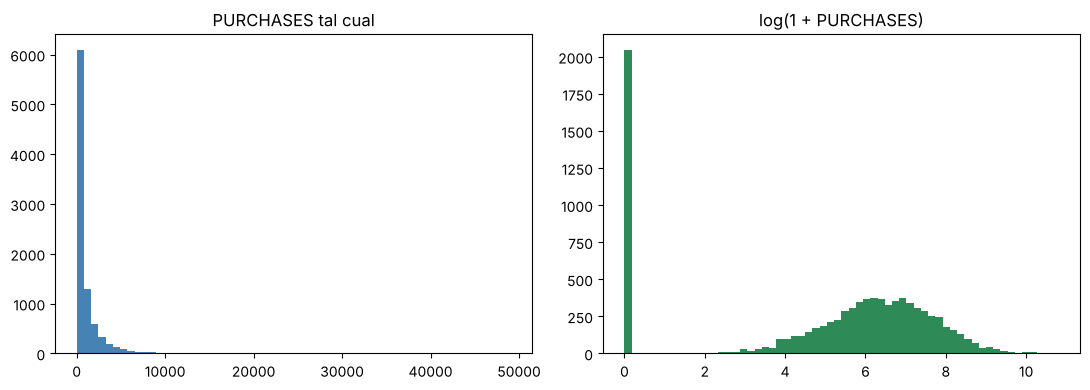

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(cc["PURCHASES"], bins=60, color="steelblue"); ax[0].set_title("PURCHASES tal cual")
ax[1].hist(np.log1p(cc["PURCHASES"]), bins=60, color="seagreen"); ax[1].set_title("log(1 + PURCHASES)")
plt.tight_layout(); plt.show()

**Interpretación.** A la izquierda casi todos los clientes se amontonan cerca de 0 y una cola larga llega hasta 49 000. A la derecha la forma es más simétrica, con una barra en 0 que son los clientes que no compran. Ahora una diferencia entre 100 y 1 000 USD pesa parecido a una entre 1 000 y 10 000: lo que importa es la **proporción**, no los dólares absolutos.

### Escalar: por qué y cómo

K-Means mide **distancias**, igual que KNN en el Día 3. Si no escalamos, el límite de crédito (en miles) aplastaría a la frecuencia de compras (entre 0 y 1). Estandarizamos con $z=(x-\text{media})/\text{desviación}$: cada variable queda con media 0 y desviación 1.

In [6]:
# Ejemplo: dos clientes que compran casi lo mismo, con límites y frecuencias muy distintos
a = {"PURCHASES": 1000, "CREDIT_LIMIT": 3000, "PURCHASES_FREQUENCY": 0.9}
b = {"PURCHASES": 1100, "CREDIT_LIMIT": 9000, "PURCHASES_FREQUENCY": 0.1}
desv = cc[list(a)].std()
for v in a:
    print(f"{v:20s} diferencia cruda {abs(a[v] - b[v]):8.1f}   diferencia en desviaciones {abs(a[v] - b[v]) / desv[v]:.2f}")

PURCHASES            diferencia cruda    100.0   diferencia en desviaciones 0.05
CREDIT_LIMIT         diferencia cruda   6000.0   diferencia en desviaciones 1.65
PURCHASES_FREQUENCY  diferencia cruda      0.8   diferencia en desviaciones 1.99


**Lee la salida.** Sin escalar, la diferencia de límite (6 000) domina y la de frecuencia (0,8) no cuenta nada, aunque un cliente compra todos los meses y el otro casi nunca. Medidas en desviaciones, la diferencia de frecuencia (≈ 2) es tan importante como la del límite (≈ 1,6).

In [7]:
preparado = cc[VARS].copy()
preparado[MONTOS] = np.log1p(preparado[MONTOS])
escalador = StandardScaler()
X = escalador.fit_transform(preparado)
X_crudo = StandardScaler().fit_transform(cc[VARS])   # misma escala, pero sin logaritmo (para comparar)
print("Forma de X:", X.shape)
print(pd.DataFrame(X, columns=VARS).agg(["mean", "std"]).round(2))

Forma de X: (8949, 9)
      BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
mean      0.0        0.0              -0.0                     0.0           0.0                 -0.0           0.0      -0.0               0.0
std       1.0        1.0               1.0                     1.0           1.0                  1.0           1.0       1.0               1.0


# 3. K-Means

### ¿Qué es K-Means?

K-Means es un algoritmo que **divide los datos en `k` grupos**. Cada grupo se representa con su **centroide**, que es el promedio de sus filas, y cada fila pertenece al grupo cuyo centroide está más cerca. El nombre lo dice: **K** es el número de grupos (lo elegimos nosotros) y **Means** significa *medias*, porque los centros son promedios. Lo que busca son grupos compactos: la menor **inercia** posible, es decir, la menor suma de distancias al cuadrado de cada fila a su centro.

**Analogía.** Un banco quiere abrir `k` agencias en una ciudad para que cada cliente quede cerca de una. (1) Ubica `k` agencias. (2) A cada cliente le asigna la más cercana. (3) Mueve cada agencia al centro de sus clientes. (4) Repite hasta que ya no conviene moverlas. Eso es K-Means.

**Qué entrega:** una etiqueta de grupo por fila y los `k` centroides, que se leen como el «cliente promedio» de cada grupo.

### Ejemplo visual: una sola variable

Antes de usar 9 variables, veamos K-Means con **una sola**: el gasto mensual de 12 clientes (USD). En el gráfico, el eje vertical es el gasto; el eje horizontal solo numera a los clientes para que los puntos no se amontonen. **El modelo usa únicamente el gasto.**

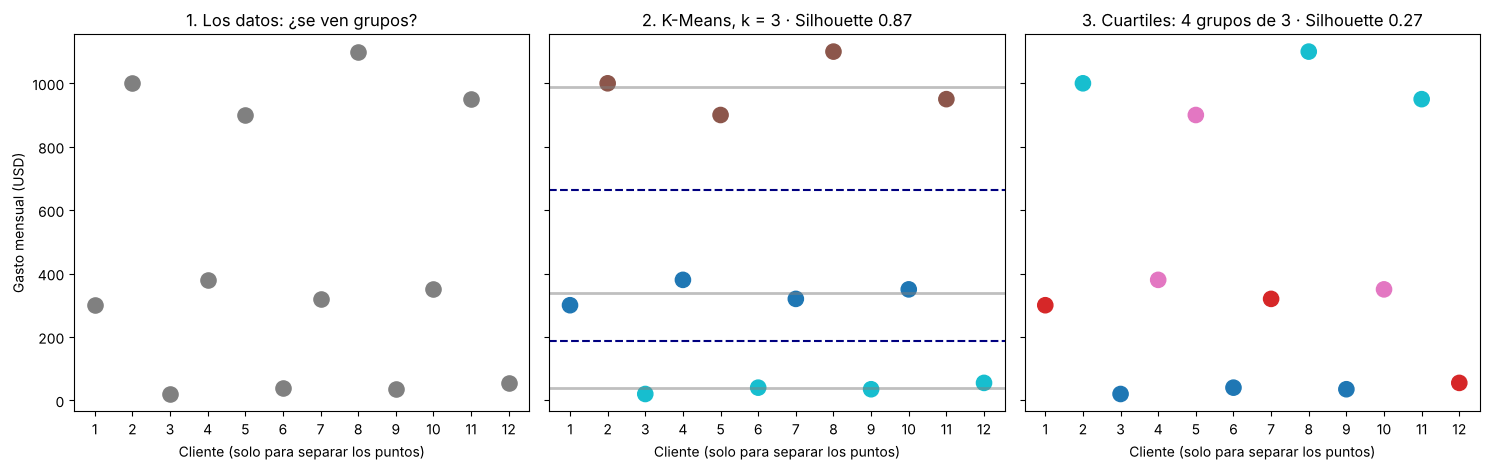

Centros: [ 37.5 337.5 987.5] | fronteras: [187.5 662.5]
Un cliente nuevo que gasta 500 va al grupo con centro 337.5


In [8]:
gasto = np.array([20, 35, 40, 55, 300, 320, 350, 380, 900, 950, 1000, 1100], dtype=float)
G = gasto.reshape(-1, 1)          # scikit-learn pide una tabla: 12 filas, 1 columna
km1 = KMeans(n_clusters=3, n_init=20, random_state=42).fit(G)
centros1 = np.sort(km1.cluster_centers_.ravel())
fronteras = (centros1[:-1] + centros1[1:]) / 2
cuartiles = np.repeat([0, 1, 2, 3], 3)  # 4 grupos de 3 clientes, en orden de gasto

cliente = np.array([3, 9, 6, 12, 1, 7, 10, 4, 5, 11, 2, 8])  # solo para separar los puntos; el modelo no lo usa
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
ax[0].scatter(cliente, gasto, s=120, color="gray"); ax[0].set_title("1. Los datos: ¿se ven grupos?")
ax[1].scatter(cliente, gasto, s=120, c=km1.labels_, cmap="tab10")
for c_ in centros1: ax[1].axhline(c_, color="gray", lw=2, alpha=0.5)
for f in fronteras: ax[1].axhline(f, ls="--", color="navy")
ax[1].set_title(f"2. K-Means, k = 3 · Silhouette {silhouette_score(G, km1.labels_):.2f}")
ax[2].scatter(cliente, gasto, s=120, c=cuartiles, cmap="tab10")
ax[2].set_title(f"3. Cuartiles: 4 grupos de 3 · Silhouette {silhouette_score(G, cuartiles):.2f}")
ax[0].set_ylabel("Gasto mensual (USD)")
for a in ax: a.set_xlabel("Cliente (solo para separar los puntos)"); a.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()
print("Centros:", centros1.round(1), "| fronteras:", fronteras.round(1))
print("Un cliente nuevo que gasta 500 va al grupo con centro", centros1[np.abs(centros1 - 500).argmin()])

**Interpretación.** A simple vista hay tres franjas de clientes y K-Means las encuentra. Cada centro es el **promedio** de su grupo: $(20+35+40+55)/4=37{,}5$; los del medio dan 337,5 y los de arriba 987,5. Las **fronteras** están en el punto medio entre dos centros: $(37{,}5+337{,}5)/2=187{,}5$ y $(337{,}5+987{,}5)/2=662{,}5$. Un cliente nuevo que gasta 500 está más cerca de 337,5 que de 987,5, así que va al grupo del medio.

Los **cuartiles** hacen 4 grupos de 3 clientes sin mirar los huecos: juntan al cliente de 55 con los de 300 y 320, y parten las nubes. Por eso su Silhouette es mucho más bajo (0,27 frente a 0,87). Veámoslo punto por punto.

In [9]:
from sklearn.metrics import silhouette_samples
tabla_puntos = pd.DataFrame({"gasto": gasto,
                             "silhouette K-Means": silhouette_samples(G, km1.labels_).round(2),
                             "silhouette cuartiles": silhouette_samples(G, cuartiles).round(2)})
print(tabla_puntos.to_string(index=False))
print("Clientes con Silhouette negativo -> K-Means:", (tabla_puntos["silhouette K-Means"] < 0).sum(),
      "| cuartiles:", (tabla_puntos["silhouette cuartiles"] < 0).sum())

 gasto  silhouette K-Means  silhouette cuartiles
  20.0                0.93                  0.91
  35.0                0.96                  0.95
  40.0                0.96                  0.93
  55.0                0.92                 -0.91
 300.0                0.81                  0.46
 320.0                0.87                  0.36
 350.0                0.88                 -0.57
 380.0                0.83                 -0.44
 900.0                0.79                 -0.78
 950.0                0.86                  0.75
1000.0                0.87                  0.84
1100.0                0.80                  0.78
Clientes con Silhouette negativo -> K-Means: 0 | cuartiles: 4


**El cliente que gasta 55, a mano.** Con K-Means está con 20, 35 y 40: $a=(35+20+15)/3=23{,}3$; el grupo vecino es el de 300 a 380: $b=(245+265+295+325)/4=282{,}5$; $s=(282{,}5-23{,}3)/282{,}5=0{,}92$, bien ubicado. Con cuartiles quedó con 300 y 320: $a=(245+265)/2=255$; el grupo vecino es el de 20, 35 y 40: $b=23{,}3$; $s=(23{,}3-255)/255=-0{,}91$, **en el grupo equivocado**. Con cuartiles, 4 de los 12 clientes quedan con Silhouette negativo; con K-Means, ninguno. Por eso los cuartiles sirven como **línea base**: agrupan sin mirar el parecido.

### Lo mismo con los 8 950 clientes: solo compras

Ahora K-Means con una sola variable real: `PURCHASES` en escala logarítmica (la explicamos en la sección 2). Igual que antes, el eje horizontal solo reparte los puntos al azar; el modelo usa únicamente las compras. Se ven tres franjas de clientes.

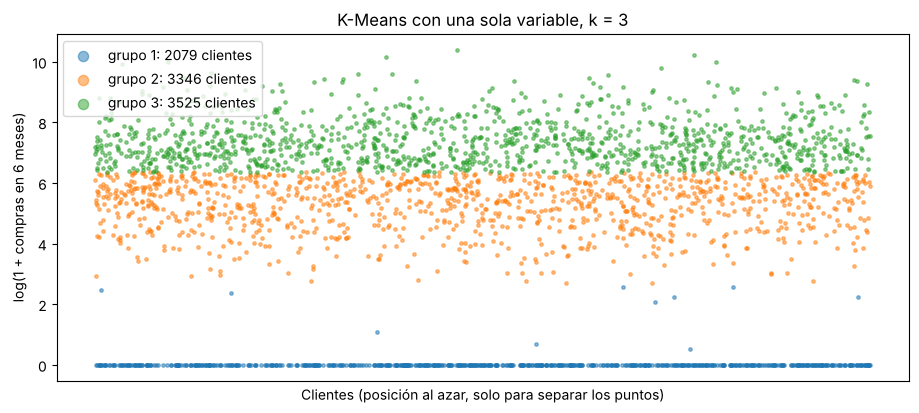

   count    min  median      max
1   2079    0.0     0.0     13.0
2   3346   14.0   240.0    573.0
3   3525  574.0  1443.0  49040.0


In [10]:
cc_tmp = pd.read_csv(ARCHIVO)
v = np.log1p(cc_tmp[["PURCHASES"]])
km_1var = KMeans(n_clusters=3, n_init=20, random_state=42).fit(v)
orden = np.argsort(km_1var.cluster_centers_.ravel())
grupo = pd.Series(km_1var.labels_).map({o: i + 1 for i, o in enumerate(orden)})
rng = np.random.RandomState(0)
muestra_idx = rng.choice(len(v), 3000, replace=False)       # 3 000 clientes para que el gráfico se lea
posicion = rng.uniform(0, 1, len(muestra_idx))                # eje horizontal al azar: el modelo no lo usa
fig, ax = plt.subplots(figsize=(11, 4.5))
for g in [1, 2, 3]:
    m = grupo.values[muestra_idx] == g
    ax.scatter(posicion[m], v["PURCHASES"].values[muestra_idx][m], s=6, alpha=0.5, label=f"grupo {g}: {(grupo == g).sum()} clientes")
ax.set(xlabel="Clientes (posición al azar, solo para separar los puntos)", ylabel="log(1 + compras en 6 meses)",
       title="K-Means con una sola variable, k = 3"); ax.set_xticks([]); ax.legend(markerscale=3); plt.show()
print(cc_tmp.groupby(grupo.values)["PURCHASES"].agg(["count", "min", "median", "max"]).round(0))

**Interpretación.** Grupo 1: unos 2 079 clientes que no compran (o casi nada). Grupo 2: compras pequeñas y medianas, aproximadamente hasta 574 USD. Grupo 3: los que más compran. Con una variable es fácil **ver** los grupos y sus fronteras, pero solo sabemos **cuánto** compran. Para distinguir a quien paga el total de quien usa avances en efectivo necesitamos las 9 variables, aunque ya no se puedan dibujar en un solo gráfico: la idea es la misma.

### K-Means paso a paso

Repite dos pasos hasta que nada cambia:

1. **Asignar:** cada punto va al centroide más cercano.
2. **Actualizar:** cada centroide se mueve al promedio de sus puntos.

Veamos una vuelta a mano con seis puntos. Empezamos (a propósito) con dos centroides mal ubicados: sobre los puntos A y B, que están juntos.

In [11]:
puntos = np.array([[1, 1], [1.5, 2], [2, 1], [5, 4], [6, 5], [5.5, 6]], dtype=float)
nombres = list("ABCDEF")
centros = puntos[[0, 1]].copy()
for vuelta in range(1, 5):
    dist = np.linalg.norm(puntos[:, None, :] - centros[None, :, :], axis=2)
    asignacion = dist.argmin(axis=1)
    print(f"Vuelta {vuelta}: centros {centros.round(2).tolist()}")
    print("   grupo de cada punto:", dict(zip(nombres, asignacion.tolist())))
    nuevos = np.vstack([puntos[asignacion == k].mean(axis=0) for k in range(2)])
    if np.allclose(nuevos, centros):
        print("   Los centros ya no cambian: el algoritmo terminó.")
        break
    centros = nuevos

Vuelta 1: centros [[1.0, 1.0], [1.5, 2.0]]
   grupo de cada punto: {'A': 0, 'B': 1, 'C': 0, 'D': 1, 'E': 1, 'F': 1}
Vuelta 2: centros [[1.5, 1.0], [4.5, 4.25]]
   grupo de cada punto: {'A': 0, 'B': 0, 'C': 0, 'D': 1, 'E': 1, 'F': 1}
Vuelta 3: centros [[1.5, 1.33], [5.5, 5.0]]
   grupo de cada punto: {'A': 0, 'B': 0, 'C': 0, 'D': 1, 'E': 1, 'F': 1}
   Los centros ya no cambian: el algoritmo terminó.


**La vuelta 1 con números.** Centro azul en A (1; 1) y centro rojo en B (1,5; 2). Distancia euclidiana de cada punto a los dos centros (la misma del KNN del Día 3):

| Punto | Coordenadas | Distancia al azul | Distancia al rojo | Va al |
|---|---|---:|---:|---|
| A | (1; 1) | 0,00 | 1,12 | azul |
| B | (1,5; 2) | 1,12 | 0,00 | rojo |
| C | (2; 1) | 1,00 | 1,12 | azul |
| D | (5; 4) | 5,00 | 4,03 | rojo |
| E | (6; 5) | 6,40 | 5,41 | rojo |
| F | (5,5; 6) | 6,73 | 5,66 | rojo |

Por ejemplo, de C a A: $\sqrt{(2-1)^2+(1-1)^2}=1{,}00$. Después, cada centro se mueve al promedio de sus puntos: azul = promedio de A y C = (1,5; 1); rojo = promedio de B, D, E y F = (4,5; 4,25).

**Lee la salida.** En la vuelta 1, el centro de B «se lleva» a D, E y F porque está algo más cerca de ellos que A. Al promediar, ese centro se mueve hacia (4,5; 4,25) y en la vuelta 2 B vuelve con A y C. En la vuelta 3 los centros ya no cambian. **Lección:** el punto de partida importa. Por eso K-Means repite el proceso con varios puntos de partida y se queda con el de menor inercia: eso controla el hiperparámetro `n_init`.

### Los hiperparámetros de K-Means

| Hiperparámetro | Qué controla | Valor de hoy |
|---|---|---|
| `n_clusters` (k) | Cuántos grupos | Se elige en la sección 4 |
| `n_init` | Cuántos puntos de partida distintos se prueban | 20 |
| `random_state` | La semilla del sorteo (resultados repetibles) | 42 |
| Preparación de los datos | Qué variables, logaritmo, escalado | 9 variables, log y z |

Comprobemos por qué importa `n_init`: con un solo punto de partida, distintas semillas pueden llegar a soluciones distintas.

In [12]:
referencia = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)
filas = []
for semilla in range(6):
    m1 = KMeans(n_clusters=4, n_init=1, random_state=semilla).fit(X)
    m20 = KMeans(n_clusters=4, n_init=20, random_state=semilla).fit(X)
    filas.append({"semilla": semilla, "inercia n_init=1": round(m1.inertia_), "inercia n_init=20": round(m20.inertia_),
                  "ARI vs referencia (n_init=1)": round(adjusted_rand_score(referencia.labels_, m1.labels_), 2)})
pd.DataFrame(filas)

,semilla,inercia n_init=1,inercia n_init=20,ARI vs referencia (n_init=1)
0,0,41171,41171,1.00
1,1,41825,41172,0.51
2,2,41172,41171,0.98
3,3,41825,41172,0.50
4,4,41825,41171,0.50
5,5,41825,41171,0.50


**Interpretación.** Con `n_init=1`, varias semillas terminan en una solución peor (inercia más alta) y con grupos bastante distintos (ARI ≈ 0,5; el ARI vale 1 cuando dos particiones coinciden). Con `n_init=20` todas llegan a la misma solución. **Siempre usa varios inicios** y fija `random_state` para que otros puedan repetir tu resultado.

### Qué hace bien K-Means y dónde falla

| Fortalezas | Limitaciones |
|---|---|
| Rápido y simple; funciona con millones de filas | Hay que elegir `k` |
| Los centros se leen como perfiles promedio | Sensible a la escala de las variables (hay que escalar) |
| Fácil de explicar | Sensible al punto de partida (usar `n_init` alto) |
| | Supone grupos más o menos redondos y de tamaño parecido: con grupos curvos los corta por la mitad |
| | Como usa promedios, los valores extremos arrastran los centros (por eso el logaritmo) |
| | Solo trabaja con variables numéricas |

# 4. ¿Cuántos grupos? Codo, Silhouette, tamaños e interpretación

**Inercia y codo.** La inercia siempre baja al aumentar `k` (con un grupo por cliente sería 0). Buscamos el **codo**: el punto desde el que agregar grupos mejora cada vez menos.

**Silhouette.** Para cada punto, $a$ = distancia promedio a los de su grupo y $b$ = distancia promedio al grupo vecino más cercano. Entonces $s=(b-a)/\max(a,b)$. Cerca de 1: bien separado; cerca de 0: en la frontera; negativo: probablemente en el grupo equivocado.

*A mano:* en una recta, grupo A = {1, 2, 3} y grupo B = {8, 9}. Para el punto 3: $a=(2+1)/2=1{,}5$; $b=(5+6)/2=5{,}5$; $s=(5{,}5-1{,}5)/5{,}5=0{,}73$.

In [13]:
# Comprobar el Silhouette a mano
recta = np.array([[1], [2], [3], [8], [9]]); grupos = np.array([0, 0, 0, 1, 1])
from sklearn.metrics import silhouette_samples
print("Silhouette de cada punto:", silhouette_samples(recta, grupos).round(2))

Silhouette de cada punto: [0.8  0.85 0.73 0.83 0.86]


In [14]:
filas = []
for nombre, datos in [("sin log", X_crudo), ("con log", X)]:
    for k in range(2, 9):
        m = KMeans(n_clusters=k, n_init=20, random_state=42).fit(datos)
        filas.append({"preparación": nombre, "k": k, "inercia": round(m.inertia_),
                      "silhouette": round(silhouette_score(datos, m.labels_, sample_size=4000, random_state=0), 3),
                      "tamaños": sorted(np.bincount(m.labels_).tolist(), reverse=True)})
tabla_k = pd.DataFrame(filas)
tabla_k

,preparación,k,inercia,silhouette,tamaños
0,sin log,2,65121,0.469,"[7699, 1250]"
1,sin log,3,55396,0.364,"[7181, 1316, 452]"
2,sin log,4,46218,0.266,"[4204, 3550, 1059, 136]"
3,sin log,5,40474,0.267,"[4016, 3470, 914, 524, 25]"
4,sin log,6,35206,0.286,"[3715, 2719, 1199, 871, 421, 24]"
5,sin log,7,32211,0.292,"[3547, 2620, 1187, 1033, 420, 118, 24]"
6,sin log,8,30070,0.292,"[3509, 2546, 1172, 1014, 507, 118, 63, 20]"
7,con log,2,58077,0.275,"[6002, 2947]"
8,con log,3,47492,0.262,"[3443, 2770, 2736]"
9,con log,4,41171,0.268,"[2770, 2444, 2438, 1297]"


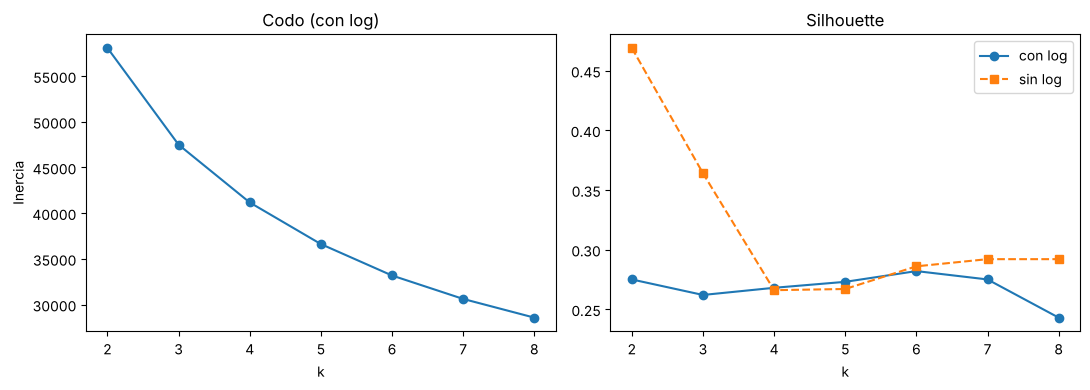

In [15]:
con_log = tabla_k[tabla_k["preparación"] == "con log"]; sin_log = tabla_k[tabla_k["preparación"] == "sin log"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(con_log.k, con_log.inercia, marker="o"); ax[0].set(title="Codo (con log)", xlabel="k", ylabel="Inercia")
ax[1].plot(con_log.k, con_log.silhouette, marker="o", label="con log")
ax[1].plot(sin_log.k, sin_log.silhouette, marker="s", ls="--", label="sin log")
ax[1].set(title="Silhouette", xlabel="k"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lee los resultados con cuidado.**

- **Sin logaritmo, k = 2 tiene el Silhouette más alto (≈ 0,47).** Parece la mejor opción, pero mira los tamaños: 7 699 clientes contra 1 250. Separa a los clientes «grandes» (saldo, límite y pagos altos) del resto. Es un resultado obvio que no ayuda a decidir nada. **Un Silhouette alto no basta.**
- **Con logaritmo, el Silhouette queda entre 0,26 y 0,28 para casi todos los `k`.** No hay una separación nítida: los clientes forman un continuo. Es normal en datos de comportamiento.
- **El codo** muestra que la inercia baja mucho hasta k = 4 y después cada grupo extra aporta menos.
- **Elegimos k = 4**: grupos de tamaño razonable (entre 1 300 y 2 800 clientes), Silhouette similar a los demás y, como veremos, **perfiles que se pueden describir y usar**. Es una decisión justificada, no un resultado automático.

# 5. Describir los grupos: del número al perfil

In [16]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
cc["segmento"] = kmeans.fit_predict(X)
print("Clientes por segmento:")
print(cc["segmento"].value_counts().sort_index())
print("\nMedianas de cada segmento (unidades originales):")
cc.groupby("segmento")[VARS].median().round(2).T

Clientes por segmento:
segmento
0    2770
1    1297
2    2438
3    2444
Name: count, dtype: int64

Medianas de cada segmento (unidades originales):


segmento,0,1,2,3
BALANCE,1864.50,84.37,1527.78,126.67
PURCHASES,1270.72,907.99,0.00,281.76
ONEOFF_PURCHASES,693.62,81.00,0.00,0.00
INSTALLMENTS_PURCHASES,390.15,483.30,0.00,109.53
CASH_ADVANCE,159.26,0.00,1272.31,0.00
PURCHASES_FREQUENCY,0.83,0.92,0.00,0.42
CREDIT_LIMIT,5950.00,4000.00,3000.00,1800.00
PAYMENTS,1680.01,1057.97,802.78,337.85
PRC_FULL_PAYMENT,0.00,0.83,0.00,0.00


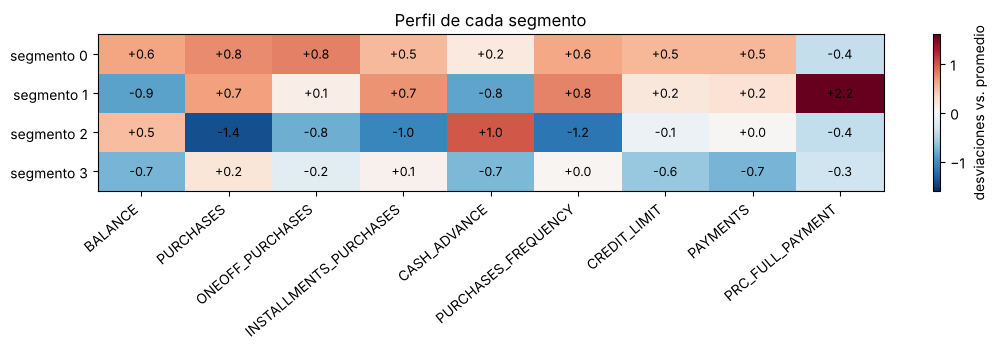

In [17]:
perfil = pd.DataFrame(X, columns=VARS).groupby(cc["segmento"].values).mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(perfil.values, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=40, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels([f"segmento {k}" for k in range(4)])
for i in range(4):
    for j in range(len(VARS)):
        ax.text(j, i, f"{perfil.values[i, j]:+.1f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="desviaciones vs. promedio"); plt.title("Perfil de cada segmento"); plt.tight_layout(); plt.show()

**Cómo leer el mapa de calor.** Rojo = el segmento está por encima del promedio en esa variable; azul = por debajo. Leemos fila por fila y ponemos un nombre que describa el comportamiento (los números 0 a 3 son etiquetas arbitrarias, no un ranking):

| Segmento | Clientes | Lo que lo distingue (medianas) | Nombre propuesto | Idea de uso |
|---|---:|---|---|---|
| 0 | 2 770 | Saldo alto (≈ 1 865), compra mucho y seguido, límite alto (≈ 5 950), casi nunca paga el total | **Compradores que financian** | Ofertas de cuotas; vigilar el endeudamiento |
| 1 | 1 297 | Saldo muy bajo (≈ 84), compra casi todos los meses, paga el total el 83 % de los meses | **Totaleros** | Programas de recompensas; bajo riesgo |
| 2 | 2 438 | Casi no compra (82 % sin compras), 99 % usa avances en efectivo (mediana ≈ 1 272), saldo alto | **Usuarios de avances en efectivo** | Posible necesidad de liquidez: revisar riesgo y ofrecer otros productos |
| 3 | 2 444 | Saldo y pagos bajos, compras pequeñas, límite bajo (≈ 1 800) | **Poco activos** | Campañas de activación |

**Cuidado con las conclusiones.** Los grupos describen comportamiento en 6 meses según **nuestras** variables. No prueban causas («paga el total porque tiene más ingresos») ni son categorías oficiales. Con otras variables o sin logaritmo saldrían otros grupos.

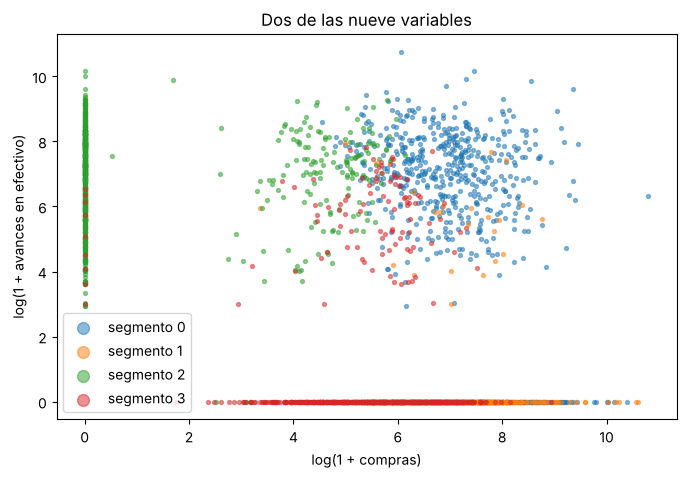

In [18]:
muestra = cc.sample(3000, random_state=1)
fig, ax = plt.subplots(figsize=(8, 5))
for k, grupo in muestra.groupby("segmento"):
    ax.scatter(np.log1p(grupo["PURCHASES"]), np.log1p(grupo["CASH_ADVANCE"]), s=8, alpha=0.5, label=f"segmento {k}")
ax.set(xlabel="log(1 + compras)", ylabel="log(1 + avances en efectivo)", title="Dos de las nueve variables")
ax.legend(markerscale=3); plt.show()

**Interpretación.** El gráfico muestra solo 2 de las 9 dimensiones, así que los colores se mezclan un poco. Aun así se ven los perfiles: la columna de puntos en «compras = 0» son los usuarios de avances; la franja inferior (avances = 0) reúne a totaleros y poco activos, que se distinguen por otras variables (saldo, pago total, límite).

# 6. Validar: línea base y otras configuraciones

En clustering no hay Train/Validation con respuestas correctas, pero sí podemos **comparar configuraciones con el mismo criterio** y contra una **línea base sencilla**. Línea base: dividir a los clientes en 4 grupos según los cuartiles de una sola variable, `PURCHASES`. Si K-Means no supera algo tan simple, no vale la pena.

In [19]:
base = pd.qcut(cc["PURCHASES"].rank(method="first"), 4, labels=False)
configs = [("Línea base: cuartiles de PURCHASES", X, base.values)]
for k in [3, 4, 5, 6]:
    configs.append((f"K-Means con log, k={k}", X, KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)))
configs.append(("K-Means sin log, k=2", X_crudo, KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(X_crudo)))
filas = []
for nombre, datos, etiquetas in configs:
    filas.append({"configuración": nombre,
                  "silhouette": round(silhouette_score(datos, etiquetas, sample_size=4000, random_state=0), 3),
                  "grupo más chico": int(np.bincount(etiquetas).min()), "grupo más grande": int(np.bincount(etiquetas).max())})
pd.DataFrame(filas)

,configuración,silhouette,grupo más chico,grupo más grande
0,Línea base: cuartiles de PURCHASES,0.135,2237,2238
1,"K-Means con log, k=3",0.262,2736,3443
2,"K-Means con log, k=4",0.268,1297,2770
3,"K-Means con log, k=5",0.273,1154,2148
4,"K-Means con log, k=6",0.282,365,2067
5,"K-Means sin log, k=2",0.469,1250,7699


**Interpretación.** La línea base de cuartiles tiene un Silhouette de apenas 0,14: separar solo por cuánto compra no produce grupos coherentes en las 9 variables. K-Means con logaritmo duplica ese valor con cualquier `k` entre 3 y 6. La configuración «sin log, k = 2» tiene el número más alto, pero ya vimos que solo separa a los clientes grandes. **Elegimos K-Means con log y k = 4** porque supera a la línea base, tiene grupos de tamaño útil, es estable con `n_init=20` y sus perfiles se pueden explicar a un área de negocio.

Así se ve la tabla de configuraciones que pide el **proyecto final** para clustering: línea base, al menos tres configuraciones y una justificación que no se quede en la métrica.

# 7. Clustering jerárquico: un árbol de fusiones

### ¿Qué es el clustering jerárquico?

Construye una **jerarquía de grupos dentro de grupos**, como un organigrama o como provincias dentro de regiones dentro de un país. Tiene dos variantes: **aglomerativa** (de abajo hacia arriba, la más usada y la que veremos) y **divisiva** (de arriba hacia abajo: empieza con todo junto y va partiendo). A diferencia de K-Means, **no hay que decidir `k` al inicio**: el resultado es un árbol, el **dendrograma**, y el número de grupos se elige al cortarlo. Es determinista (siempre da el mismo resultado), pero lento con muchos datos, porque compara todos los pares de filas.

### Cómo funciona

El método **aglomerativo** empieza con cada cliente como su propio grupo y va **uniendo** los dos grupos más cercanos, paso a paso, hasta que queda uno solo. El **dendrograma** dibuja esas uniones: la altura de cada unión indica qué tan distintos eran los grupos que se juntaron. Para obtener `k` grupos, se «corta» el árbol con una línea horizontal.

*A mano:* cinco puntos en una recta: A = 1, B = 2, C = 6, D = 7, E = 15. Primero se calcula la **matriz de distancias** entre todos los pares:

| | A = 1 | B = 2 | C = 6 | D = 7 | E = 15 |
|---|---:|---:|---:|---:|---:|
| A | — | **1** | 5 | 6 | 14 |
| B | | — | 4 | 5 | 13 |
| C | | | — | **1** | 9 |
| D | | | | — | 8 |

| Paso | Distancia menor | Se unen | Centro del grupo nuevo |
|---|---|---|---|
| 1 | 1 (A-B) | A y B | 1,5 |
| 2 | 1 (C-D) | C y D | 6,5 |
| 3 | 6,5 − 1,5 = 5 | {A, B} y {C, D} | 4 |
| 4 | 15 − 4 = 11 | {A, B, C, D} y E | — |

**Regla de cada paso:** buscar la menor distancia, unir esos dos grupos, recalcular las distancias del grupo nuevo y repetir. **Cortar el árbol:** una línea horizontal a altura 3 deja 3 grupos, {A, B}, {C, D} y {E}; a altura 8 deja 2, {A, B, C, D} y {E}. Un buen corte suele estar justo antes de un salto grande de altura.

**Linkage** es la regla para medir la distancia entre dos grupos: *ward* (la unión que menos aumenta la variación interna), *complete* (los puntos más lejanos), *average* (el promedio) o *single* (los puntos más cercanos). El método jerárquico compara todos los pares de puntos, así que es lento con muchos datos: usamos una muestra de 2 000 clientes.

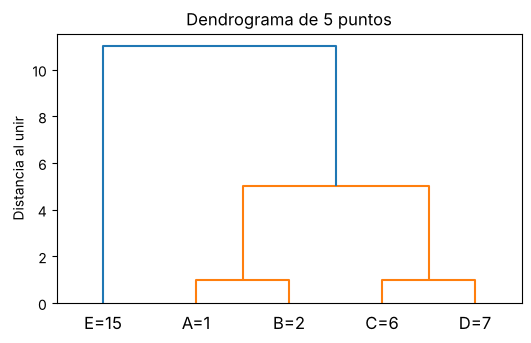

In [20]:
recta5 = np.array([[1], [2], [6], [7], [15]], dtype=float)
plt.figure(figsize=(6, 3.5))
dendrogram(linkage(recta5, method="centroid"), labels=["A=1", "B=2", "C=6", "D=7", "E=15"])
plt.title("Dendrograma de 5 puntos"); plt.ylabel("Distancia al unir"); plt.show()

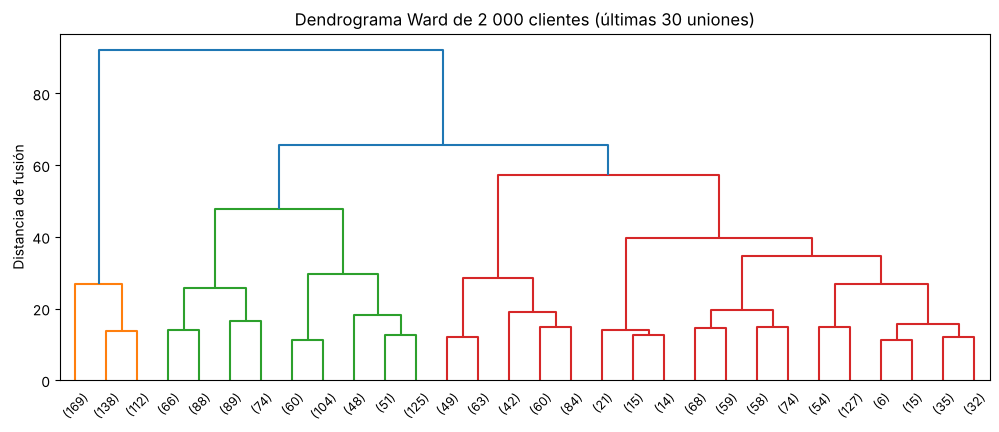

In [21]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X), 2000, replace=False)
X_muestra = X[idx]
Z = linkage(X_muestra, method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_font_size=9)
plt.title("Dendrograma Ward de 2 000 clientes (últimas 30 uniones)"); plt.ylabel("Distancia de fusión"); plt.show()

**Lee el dendrograma.** Los números entre paréntesis en la base indican cuántos clientes agrupa cada rama. Las uniones de arriba ocurren a gran altura: son grupos muy distintos. Un corte justo debajo de las tres últimas uniones deja 4 grupos. Ahora comparamos distintas reglas de unión.

In [22]:
filas = []
for regla in ["ward", "complete", "average", "single"]:
    etiquetas = AgglomerativeClustering(n_clusters=4, linkage=regla).fit_predict(X_muestra)
    filas.append({"linkage": regla, "tamaños": sorted(np.bincount(etiquetas).tolist(), reverse=True),
                  "silhouette": round(silhouette_score(X_muestra, etiquetas), 3),
                  "ARI vs K-Means": round(adjusted_rand_score(cc["segmento"].values[idx], etiquetas), 2)})
pd.DataFrame(filas)

,linkage,tamaños,silhouette,ARI vs K-Means
0,ward,"[705, 578, 419, 298]",0.233,0.53
1,complete,"[928, 588, 434, 50]",0.182,0.28
2,average,"[1942, 51, 6, 1]",0.248,0.00
3,single,"[1997, 1, 1, 1]",0.224,-0.00


**Interpretación.** *Average* y *single* tienen un Silhouette parecido o mayor que Ward, pero mira los tamaños: dejan casi todos los clientes en un solo grupo y aíslan unos pocos casos extremos. Son inútiles para segmentar. **Ward** produce grupos equilibrados y coincide moderadamente con K-Means (ARI ≈ 0,5): ambos encuentran una estructura parecida, no idéntica. De nuevo, la métrica sola engaña; hay que mirar tamaños y perfiles.

**¿Cuándo preferir cada método?**

| | K-Means | Jerárquico (aglomerativo) |
|---|---|---|
| ¿Cómo agrupa? | Alrededor de `k` centros | Uniendo los grupos más cercanos |
| ¿Cuándo se elige `k`? | Antes de empezar | Después, al cortar el árbol |
| Tamaño de datos | Millones de filas | Cientos o pocos miles |
| ¿Mismo resultado siempre? | Depende del inicio (usar `n_init`) | Sí, es determinista |
| Forma de los grupos | Redondos y de tamaño parecido | Depende del linkage |
| Qué entrega | Grupos y centros | Dendrograma y grupos al cortar |
| Ejemplo | Segmentar 8 950 clientes | Agrupar 24 provincias o 30 países |

# 8. Cierre: cómo defender un clustering

1. **Pregunta clara:** ¿para qué quiero los grupos? (aquí: diseñar acciones por tipo de cliente).
2. **Preparación declarada:** qué variables, cómo traté faltantes, logaritmo y escalado.
3. **Elección de `k` con varias evidencias:** codo, Silhouette, tamaños y, sobre todo, interpretación.
4. **Comparación:** línea base y otras configuraciones de hiperparámetros.
5. **Estabilidad:** `n_init` alto y misma solución con otras semillas.
6. **Perfiles en unidades originales** y nombres que describan comportamiento.
7. **Limitaciones:** los grupos dependen de las variables y la preparación; no prueban causas.

### Actividad autónoma

1. Quita el logaritmo y repite con k = 4. ¿Qué perfiles cambian? ¿Cuál solución explicarías mejor a un gerente?
2. Agrega `CASH_ADVANCE_FREQUENCY` y `MINIMUM_PAYMENTS` a las variables. ¿Aparece un segmento nuevo con k = 5?
3. Cambia la línea base: cuartiles de `BALANCE` en lugar de `PURCHASES`. ¿K-Means sigue ganando?
4. Escribe en 150 palabras qué acción comercial o de riesgo propondrías para el segmento de avances en efectivo, y qué dato adicional pedirías antes de aplicarla.